# Crystal structure factors

This notebook calculates Silicon's structure factors with pyEMAPS, step by step. It follows the
*si_csf.py* sample, one step per cell.

You'll:

1. calculate X-ray structure factors and read pyEMAPS' table;
2. see which reflections the diamond structure forbids, and why;
3. turn X-ray structure factors into electron ones, and see how the high voltage changes them;
4. look at the absorption structure factors.

**Structure factors in brief.** A crystal diffracts into the reflections $\mathbf g = (hkl)$ of
its reciprocal lattice. The **structure factor** $F_{\mathbf g}$ is the amplitude and phase of the
wave that the atoms of one unit cell scatter into $\mathbf g$:

$$F_{\mathbf g} = \sum_j f_j(s)\, e^{-B_j s^2}\, e^{2\pi i\, \mathbf g \cdot \mathbf r_j}$$

The sum runs over the atoms $j$ of the cell, at positions $\mathbf r_j$. $f_j(s)$ is the atom's
**scattering factor**, which falls as the scattering angle grows; $s = \sin\theta/\lambda =
1/(2d)$, with $d$ the spacing of the planes. $e^{-B_j s^2}$ is the Debye-Waller factor: thermal
vibrations smear each atom out and weaken the high-angle reflections. X-rays are scattered by the
atoms' electrons, and electrons by their electrostatic potential, so the two have different
scattering factors.

Structure factors set the intensities of every diffraction pattern: in kinematic theory each
reflection's intensity is $|F_{\mathbf g}|^2$, and in dynamic theory they make up the matrix
that couples the beams.

**Requirements.** pyEMAPS on Windows, with Python 3.12 to 3.15, and Jupyter in the same
environment:

```
pip install pyemaps jupyter
```

## Step 1: Import pyEMAPS and load a crystal

The crystal data lists one Silicon atom, at (1/8, 1/8, 1/8), with its Debye-Waller factor $B$
in Å² and its occupancy. The space group, 227 (Fd-3m) in its origin choice 2, places the other
seven atoms of the cubic cell.

In [1]:
import math
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np

from pyemaps import Crystal

print('pyEMAPS', version('pyemaps'))

silicon = Crystal.from_builtin('Silicon')
print(silicon)

pyEMAPS 2.1.1.dev11
Crystal name: Silicon dw iso
cell: 5.4307 5.4307 5.4307 90.0 90.0 90.0
SI 0.125 0.125 0.125 0.4668 1.00
spg: 227 2


## Step 2: X-ray structure factors

`generateCSF` calculates structure factors of four types, chosen by `sftype`:

| `sftype` | Structure factors | Unit |
|---|---|---|
| 1 | X-ray | electrons |
| 2 | electron, $V_{\mathbf g}$ | volts |
| 3 | electron, $U_{\mathbf g}$ | 1/Å² |
| 4 | electron absorption, $U'_{\mathbf g}$ | 1/Å² |

It includes every reflection with $s = \sin\theta/\lambda$ up to `smax`, one from each set of
symmetry-equivalent reflections. `aptype=1` gives each one as an amplitude and a phase, in
degrees. `printCSF` prints the result as a table.

In [2]:
xray = silicon.generateCSF(kv=100, smax=0.5, sftype=1, aptype=1)
silicon.printCSF(xray)

-----X-ray Structure Factors----- 
     crystal		: Silicon
     h k l 		: Miller Index
     s-w   		: Sin(theta)/Wavelength <= 0.5
     d-s   		: D-Spacing
 
 h   k    l        s-w             d-s          amplitude         phase      

 1   1   1    0.1594684869    3.1354157925    58.89618        180.000000     
 0   0   2    0.1841383278    2.7153499126    1.171896e-06    180.000000     
 0   2   2    0.2604109347    1.9200422764    67.56880        180.000000     
 1   1   3    0.3053588867    1.6374175549    44.24471        180.000000     
 2   2   2    0.3189369738    1.5677078962    1.458770e-05    0.000000       
 0   0   4    0.3682766557    1.3576749563    56.41311        180.000000     
 1   3   3    0.4013201892    1.2458879948    37.71913        0.000000       
 0   2   4    0.4117458463    1.2143412828    1.703731e-19    0.000000       
 2   2   4    0.4510449767    1.1085369587    48.80523        0.000000       
 1   1   5    0.4784054160    1.0451387167    32.76954       

The columns are the Miller indices, $s$ (`s-w`), the spacing $d$ (`d-s`) in Å, and the
structure factor. The result is a list of dictionaries: the first holds the inputs, and each one
after it a reflection:

In [3]:
print(xray[0])
print(xray[1])

print('s = 1/(2d) for every reflection:',
      all(math.isclose(sf['sw'], 1 / (2 * sf['ds']), rel_tol=1e-5) for sf in xray[1:]))

{'kv': 100, 'smax': 0.5, 'sftype': 1, 'aptype': 1}
{'hkl': (1, 1, 1), 'sw': 0.15946848690509796, 'ds': 3.13541579246521, 'amp_re': 58.896183013916016, 'phase_im': 180.0}
s = 1/(2d) for every reflection: True


(1 1 5) and (3 3 3) have the same spacing, since $1^2 + 1^2 + 5^2 = 3^2 + 3^2 + 3^2$, but
they aren't symmetry-equivalent, so both are listed.

### Amplitude and phase, or real and imaginary parts

Every phase is 0° or 180°. Silicon's structure has a center of inversion, and origin choice 2
puts the origin on it, so the terms for the atoms at $\mathbf r$ and $-\mathbf r$ add up to a
real number. `aptype=0`, the default, gives the same structure factors as real and imaginary
parts:

In [4]:
parts = silicon.generateCSF(kv=100, smax=0.5, sftype=1, aptype=0)

print('  h k l    amplitude    phase      real         imaginary')
for ap, ri in zip(xray[1:6], parts[1:6]):
    print(f"  {ap['hkl']}  {ap['amp_re']:10.4f}  {ap['phase_im']:6.1f}°   {ri['amp_re']:10.4f}  {ri['phase_im']:10.4f}")

  h k l    amplitude    phase      real         imaginary
  (1, 1, 1)     58.8962   180.0°     -58.8962      0.0000
  (0, 0, 2)      0.0000   180.0°      -0.0000      0.0000
  (0, 2, 2)     67.5688   180.0°     -67.5688      0.0000
  (1, 1, 3)     44.2447   180.0°     -44.2447      0.0000
  (2, 2, 2)      0.0000     0.0°       0.0000      0.0000


## Step 3: Forbidden reflections

(0 0 2), (2 2 2) and (0 2 4) are about a million times weaker than the others: zero, to the
precision of the calculation. To see why, split the sum over the atoms into the atom's scattering factor and a
**geometric factor** $G_{\mathbf g}$, since all eight atoms are Silicon:

$$F_{\mathbf g} = f(s)\, e^{-Bs^2}\, G_{\mathbf g}, \qquad
G_{\mathbf g} = \sum_{j=1}^{8} e^{2\pi i\, \mathbf g \cdot \mathbf r_j}$$

The diamond structure is two face-centred cubic lattices, shifted by a quarter of the cell
diagonal. With origin choice 2, the atoms are at $\pm(1/8, 1/8, 1/8)$ plus the four
face-centring translations. The geometric factor is $\pm 4\sqrt 2$ for $h, k, l$ all odd, $\pm 8$
for all even with $h + k + l$ a multiple of 4, and zero otherwise: there, the two lattices'
waves cancel.

In [5]:
fcc = np.array([[0, 0, 0], [0, 0.5, 0.5], [0.5, 0, 0.5], [0.5, 0.5, 0]])
positions = np.vstack([fcc + 0.125, fcc - 0.125])      # the eight atoms of the cell


def geometric_factor(hkl):
    return np.exp(2j * np.pi * positions @ np.array(hkl)).sum().real


print('  h k l      G        F (pyEMAPS)')
for sf in xray[1:]:
    print(f"  {sf['hkl']}  {geometric_factor(sf['hkl']):+7.3f}   {sf['amp_re']:9.3g}")

  h k l      G        F (pyEMAPS)
  (1, 1, 1)   -5.657        58.9
  (0, 0, 2)   +0.000    1.17e-06
  (0, 2, 2)   -8.000        67.6
  (1, 1, 3)   -5.657        44.2
  (2, 2, 2)   -0.000    1.46e-05
  (0, 0, 4)   -8.000        56.4
  (1, 3, 3)   +5.657        37.7
  (0, 2, 4)   -0.000     1.7e-19
  (2, 2, 4)   +8.000        48.8
  (1, 1, 5)   +5.657        32.8
  (3, 3, 3)   +5.657        32.8


Where $G_{\mathbf g}$ isn't zero, $F_{\mathbf g}/G_{\mathbf g}$ is the scattering factor of
one Silicon atom, with its Debye-Waller factor. Plotted against $s$ for all reflections up to
$s$ = 1 1/Å, it is one smooth curve. At $s = 0$ it would reach 14, Silicon's number of
electrons: X-rays are scattered by the electrons, and at higher angles the waves from different
parts of the electron cloud cancel more and more.

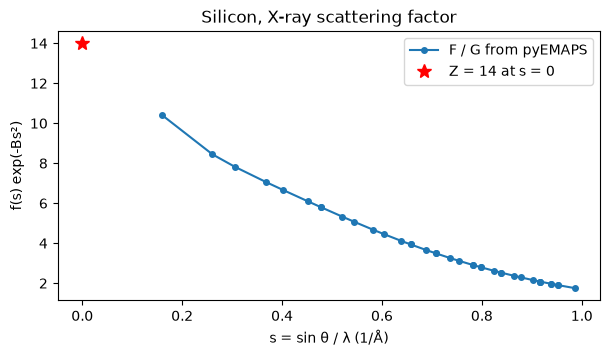

In [6]:
xray_all = silicon.generateCSF(kv=100, smax=1.0, sftype=1, aptype=0)[1:]
allowed = [sf for sf in xray_all if abs(geometric_factor(sf['hkl'])) > 1e-6]
s = np.array([sf['sw'] for sf in allowed])
f = np.array([sf['amp_re'] / geometric_factor(sf['hkl']) for sf in allowed])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(s, f, 'o-', markersize=4, label='F / G from pyEMAPS')
ax.plot(0, 14, 'r*', markersize=10, label='Z = 14 at s = 0')
ax.set_xlabel('s = sin θ / λ (1/Å)')
ax.set_ylabel('f(s) exp(-Bs²)')
ax.set_title('Silicon, X-ray scattering factor')
ax.legend()
plt.show()

In real Silicon, (2 2 2) is weak but not zero: the covalent bonds put electrons between the
atoms, which a model of spherical atoms leaves out. Measuring such small differences in
structure factors measures the bonding.

## Step 4: Electron structure factors

Electrons are scattered by the electrostatic potential of the crystal. Its Fourier coefficients
are the electron structure factors $V_{\mathbf g}$, in volts (`sftype=2`). The potential comes
from the nucleus, of charge $+Ze$, screened by the electrons, so the electron scattering factor
follows from the X-ray one by the **Mott-Bethe formula**:

$$f^e(s) = \frac{m_0 e^2}{8\pi\varepsilon_0 h^2}\, \frac{Z - f^X(s)}{s^2}$$

with $m_0$ the electron rest mass. Summed over the cell like $F_{\mathbf g}$, and divided by the
cell volume $\Omega$:

$$V_{\mathbf g} = \frac{h^2}{2\pi m_0 e\, \Omega}\, F^e_{\mathbf g}, \qquad
F^e_{\mathbf g} = \frac{m_0 e^2}{8\pi\varepsilon_0 h^2}\,
\frac{Z\, e^{-Bs^2} G_{\mathbf g} - F^X_{\mathbf g}}{s^2}$$

The cell below applies it to pyEMAPS' X-ray structure factors and compares the result with its
$V_{\mathbf g}$:

In [7]:
h, m0, e, eps0 = 6.62607015e-34, 9.1093837015e-31, 1.602176634e-19, 8.8541878128e-12  # SI

x, y, z, B, occupancy = (float(v) for v in silicon.atoms[0].loc)
Z = 14
volume = silicon.cell.a ** 3                                   # Å³
mott_bethe = m0 * e**2 / (8 * math.pi * eps0 * h**2) * 1e-10    # Å
to_volts = h**2 / (2 * math.pi * m0 * e * volume * 1e-30) * 1e-10   # V per Å

volts = silicon.generateCSF(kv=100, smax=1.0, sftype=2, aptype=0)[1:]

print('  h k l      V_g (pyEMAPS)   V_g (Mott-Bethe)')
worst = 0
for fx, fv in zip(xray_all, volts):
    G = geometric_factor(fx['hkl'])
    if abs(G) < 1e-6:
        continue
    s2 = fx['sw'] ** 2
    Fe = mott_bethe * (Z * math.exp(-B * s2) * G - fx['amp_re']) / s2
    V = to_volts * Fe
    worst = max(worst, abs(V / fv['amp_re'] - 1))
    if fx['sw'] < 0.5:
        print(f"  {fx['hkl']}   {fv['amp_re']:+8.4f} V       {V:+8.4f} V")
print(f'Largest relative difference, all {len(volts)} reflections: {worst:.1e}')

  h k l      V_g (pyEMAPS)   V_g (Mott-Bethe)
  (1, 1, 1)    -5.4482 V        -5.4481 V
  (0, 2, 2)    -4.3194 V        -4.3193 V
  (1, 1, 3)    -2.4229 V        -2.4229 V
  (0, 0, 4)    -2.5698 V        -2.5698 V
  (1, 3, 3)    +1.5877 V        +1.5877 V
  (2, 2, 4)    +1.8656 V        +1.8655 V
  (1, 1, 5)    +1.2004 V        +1.2004 V
  (3, 3, 3)    +1.2004 V        +1.2004 V
Largest relative difference, all 55 reflections: 1.3e-05


They agree to about $10^{-5}$. The electron structure factors fall faster with $s$ than the
X-ray ones, because of the $1/s^2$: electrons are scattered mostly at small angles.

Electrons are also scattered far more strongly. For X-rays, each electron of the atom scatters
with an amplitude of $r_e$ = 2.818 × 10⁻⁵ Å, the classical electron radius, so an atom's X-ray
scattering amplitude is $r_e f^X$. Its electron scattering amplitude is $f^e$, also in Å. For
(1 1 1):

In [8]:
r_e = 2.8179403262e-5                     # Å
s2 = xray_all[0]['sw'] ** 2
f_x = xray_all[0]['amp_re'] / geometric_factor((1, 1, 1))     # with the Debye-Waller factor
f_e = mott_bethe * (Z * math.exp(-B * s2) - f_x) / s2
print(f'X-ray amplitude r_e f_x = {r_e * f_x:.2e} Å, electron amplitude f_e = {f_e:.2f} Å, '
      f'ratio {f_e / (r_e * f_x):.0f}')

X-ray amplitude r_e f_x = 2.93e-04 Å, electron amplitude f_e = 3.22 Å, ratio 10982


The amplitude is about $10^4$ times larger for electrons, and the intensity, its square,
about $10^8$ times. That's why electron diffraction works on nanometre-sized crystals, and why
electrons are scattered many times on their way through a sample.

## Step 5: The high voltage

The Bloch wave equations, in the [dynamic diffraction notebook](si_bloch.ipynb), use
$V_{\mathbf g}$ in other units, $U_{\mathbf g}$ in 1/Å² (`sftype=3`):

$$U_{\mathbf g} = \frac{2 m e}{h^2}\, V_{\mathbf g}, \qquad m = \gamma m_0, \quad
\gamma = 1 + \frac{eE}{m_0 c^2}$$

$V_{\mathbf g}$ is a property of the crystal alone, but $U_{\mathbf g}$ includes the electron's
relativistic mass $m$, which grows with the high voltage $E$. Faster electrons are scattered
more strongly, in proportion to $\gamma$:

In [9]:
c = 299792458.0
U0 = None
print('  kV    γ        V_111 (V)   U_111 (1/Å²)   U ratio   γ ratio')
for kv in (100, 200, 300):
    V111 = silicon.generateCSF(kv=kv, smax=0.2, sftype=2, aptype=1)[1]['amp_re']
    U111 = silicon.generateCSF(kv=kv, smax=0.2, sftype=3, aptype=1)[1]['amp_re']
    gamma = 1 + e * kv * 1e3 / (m0 * c**2)
    if U0 is None:
        U0, gamma0 = U111, gamma
    print(f'  {kv}   {gamma:.4f}   {V111:.4f}      {U111:.5f}        '
          f'{U111 / U0:.4f}    {gamma / gamma0:.4f}')

print()
print(f'U_111 from the formula at 100 kV: {2 * gamma0 * m0 * e * V111 / h**2 * 1e-20:.5f} 1/Å²')

  kV    γ        V_111 (V)   U_111 (1/Å²)   U ratio   γ ratio
  100   1.1957   5.4482      0.04331        1.0000    1.0000
  200   1.3914   5.4482      0.05040        1.1637    1.1637
  300   1.5871   5.4482      0.05749        1.3273    1.3273

U_111 from the formula at 100 kV: 0.04331 1/Å²


$V_{\mathbf g}$ stays the same, and $U_{\mathbf g}$ grows with $\gamma$. The extinction
distance $\xi_{\mathbf g} = K/|U_{\mathbf g}|$, the thickness over which the intensity passes
from the direct beam to a reflection and back, depends on the voltage through both $K$ and
$U_{\mathbf g}$; the [dynamic diffraction notebook](si_bloch.ipynb) calculates it at 200 kV.

## Step 6: Absorption

Some electrons lose energy in the sample, mostly to the atoms' thermal vibrations, and leave the
Bragg beams. The dynamic theory includes this as an imaginary part of the potential,
$U_{\mathbf g} + i U'_{\mathbf g}$. `sftype=4` gives the absorption structure factors
$U'_{\mathbf g}$. They are a few percent of $U_{\mathbf g}$, and fall more slowly with $s$:

In [10]:
U = silicon.generateCSF(kv=200, smax=1.0, sftype=3, aptype=1)[1:]
Ua = silicon.generateCSF(kv=200, smax=1.0, sftype=4, aptype=1)[1:]

print("  h k l      s        |U_g|      |U'_g|     |U'_g| / |U_g|")
for u, ua in zip(U, Ua):
    if abs(geometric_factor(u['hkl'])) > 1e-6 and u['sw'] < 0.75:
        print(f"  {u['hkl']}  {u['sw']:.3f}   {u['amp_re']:.5f}   {ua['amp_re']:.6f}     "
              f"{ua['amp_re'] / u['amp_re']:.1%}")

  h k l      s        |U_g|      |U'_g|     |U'_g| / |U_g|
  (1, 1, 1)  0.159   0.05040   0.000550     1.1%
  (0, 2, 2)  0.260   0.03996   0.000719     1.8%
  (1, 1, 3)  0.305   0.02241   0.000486     2.2%
  (0, 0, 4)  0.368   0.02377   0.000646     2.7%
  (1, 3, 3)  0.401   0.01469   0.000440     3.0%
  (2, 2, 4)  0.451   0.01726   0.000586     3.4%
  (1, 1, 5)  0.478   0.01110   0.000401     3.6%
  (3, 3, 3)  0.478   0.01110   0.000401     3.6%
  (0, 4, 4)  0.521   0.01368   0.000539     3.9%
  (1, 3, 5)  0.545   0.00899   0.000370     4.1%
  (0, 2, 6)  0.582   0.01137   0.000498     4.4%
  (3, 3, 5)  0.604   0.00755   0.000342     4.5%
  (4, 4, 4)  0.638   0.00970   0.000458     4.7%
  (1, 1, 7)  0.658   0.00650   0.000313     4.8%
  (1, 5, 5)  0.658   0.00650   0.000313     4.8%
  (2, 4, 6)  0.689   0.00844   0.000423     5.0%
  (1, 3, 7)  0.707   0.00568   0.000291     5.1%
  (3, 5, 5)  0.707   0.00568   0.000291     5.1%
  (0, 0, 8)  0.737   0.00743   0.000393     5.3%


Small as they are, the absorption structure factors matter in thick samples: they make the
thickness fringes fade, and they make some Bloch waves fade faster than others. The
[scattering matrix notebook](si_scm.ipynb) shows their effect inside the dynamic
calculation.

## Step 7: More reflections

`smax` sets how many reflections are included. Their number grows as `smax` cubed, since they
fill a sphere in reciprocal space:

In [11]:
for smax in (0.5, 1.0, 1.5, 2.0):
    n = len(silicon.generateCSF(smax=smax)) - 1
    print(f'smax = {smax}: {n:3d} reflections')

smax = 0.5:  11 reflections
smax = 1.0:  55 reflections
smax = 1.5: 152 reflections
smax = 2.0: 323 reflections


If `smax` includes more reflections than the backend can hold, `generateCSF` raises a
`CSFError`; lower `smax` and try again.

## Going further: the sample

The *si_csf.py* sample calculates all four types, in both formats, with `smax` = 1.0, and
returns them in a dictionary keyed by `(sftype, aptype)`. pyEMAPS installs the samples as
`pyemaps.samples`:

In [12]:
from pyemaps.samples.si_csf import AP_TYPES, SF_TYPES, generate_structure_factors

results = generate_structure_factors(verbose=False)
for (sftype, aptype), sfs in results.items():
    print(f'{sftype}, {aptype}: {len(sfs) - 1} reflections, {SF_TYPES[sftype]}, {AP_TYPES[aptype]}')

1, 1: 55 reflections, X-ray structure factors, amplitude and phase
1, 0: 55 reflections, X-ray structure factors, real and imaginary parts
2, 1: 55 reflections, electron structure factors, in volts, amplitude and phase
2, 0: 55 reflections, electron structure factors, in volts, real and imaginary parts
3, 1: 55 reflections, electron structure factors, in 1/Å², amplitude and phase
3, 0: 55 reflections, electron structure factors, in 1/Å², real and imaginary parts
4, 1: 55 reflections, electron absorption structure factors, in 1/Å², amplitude and phase
4, 0: 55 reflections, electron absorption structure factors, in 1/Å², real and imaginary parts


## Try it yourself

1. **A crystal without a center of inversion.** Calculate the X-ray structure factors of
   `GalliumArsenide`. It has Silicon's arrangement of atoms, with Gallium and Arsenic on the two
   face-centred lattices. Why is (0 0 2) no longer zero, and why aren't the phases 0° or 180°?
2. **A lighter atom.** Repeat Step 3 for `Diamond`, which has the same structure with Carbon.
   Where does its scattering factor curve start at $s = 0$?
3. **Face-centred cubic.** `Aluminium` has one atom per lattice point. Which of Silicon's
   forbidden reflections does it have?
4. **Absorption.** In a thick sample, which reflection's intensity would you expect to fade
   faster with thickness, (1 1 1) or (0 0 8)? Why?

## Next

- The [dynamic diffraction notebook](si_bloch.ipynb): the structure factors at work, in CBED
  patterns and thickness fringes.
- The [scattering matrix notebook](si_scm.ipynb): the matrix of the Bloch wave calculation,
  built from $U_{\mathbf g}$ and $U'_{\mathbf g}$.
- The references for [`generateCSF`](https://emlab-solutions.github.io/pyemaps/api/crystals.html#pyemaps.crystals.Crystal.generateCSF)
  and [`printCSF`](https://emlab-solutions.github.io/pyemaps/api/crystals.html#pyemaps.crystals.Crystal.printCSF).

## Further reading

J. C. H. Spence and J. M. Zuo, *Electron Microdiffraction* (Plenum, New York, 1992),
[doi:10.1007/978-1-4899-2353-0](https://doi.org/10.1007/978-1-4899-2353-0):

- chapter 3, *Theory*, for Steps 4 to 6;
- chapter 4, *The Measurement of Low-Order Structure Factors and Thickness*, for measuring the
  bonding mentioned in Step 3.

J. M. Zuo and J. C. H. Spence, *Advanced Transmission Electron Microscopy* (Springer, New York,
2017), [doi:10.1007/978-1-4939-6607-3](https://doi.org/10.1007/978-1-4939-6607-3):

- chapter 2, *Electron Waves and Wave Propagation*, for Step 5;
- chapter 4, *Kinematical Theory of Electron Diffraction*, for Steps 2 to 4;
- chapter 12, *Crystal Structure and Bonding*, for the bonding mentioned in Step 3.